# Exercise 50 – Learning a rotation with linear layers

**Week 9 · Neural networks**

Six points are mapped to the same points rotated by 30°. A linear layer
$\mathbf{y} = W\mathbf{x} + \mathbf{b}$ should be able to learn this map. Once
trained, we apply the network repeatedly: if it really learned a rotation, the
points should travel around a circle.

In the second part the points are shifted away from the origin, so the
rotation is about another point – and now the bias is essential.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

from comphy.plotting import iteration_colors, setup_axes
from comphy.training import fit

torch.manual_seed(0)

points = torch.tensor([[0.5, 0], [1, 0], [1.5, 0], [0.5, 0.2], [1, 0.2], [1.5, 0.7]])
rotated = torch.tensor([[0.433, 0.25], [0.866, 0.5], [1.299, 0.75],
                        [0.333, 0.4232], [0.766, 0.6732], [0.949, 1.3562]])

shift = torch.tensor([2.0, 1.0])
points_shifted, rotated_shifted = points + shift, rotated + shift

LIMS = (-2.25, 4.25)


def show_training_data(x, y):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].scatter(*x.T, s=40, color="black")
    axes[1].scatter(*y.T, s=40, color="red")
    for ax, title in zip(axes, ["Training input", "Training output"]):
        setup_axes(ax, xlim=LIMS, ylim=LIMS, title=title, equal=True)
    plt.show()


def plot_iterations(ax, model, start, n=10, title=None):
    """Apply ``model`` ``n`` times starting from ``start``."""
    p = start.clone()
    ax.scatter(*p.T, color="black", s=15, label="start")
    with torch.no_grad():
        for i, color in enumerate(iteration_colors(n)):
            p = model(p)
            ax.scatter(*p.T, color=color, s=15, label=f"iteration {i + 1}" if i in (0, n - 1) else None)
    ax.text(0.0, -0.15, parameter_text(model), transform=ax.transAxes, fontsize=8, va="top",
            family="monospace")
    setup_axes(ax, xlim=LIMS, ylim=LIMS, title=title, equal=True)
    ax.legend(fontsize=7, loc="lower right")


def parameter_text(model):
    lines = []
    for name, p in model.named_parameters():
        rows = p.detach().reshape(p.shape[0], -1).tolist()
        lines.append(f"{name:>8} = " + "  ".join("[" + " ".join(f"{v:5.2f}" for v in r) + "]"
                                             for r in rows))
    return "\n".join(lines)


def compare_models(x, y, models, titles, steps):
    fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 6.5))
    for ax, model, title in zip(axes, models, titles):
        loss = fit(model, x, y, steps=steps)[-1]
        plot_iterations(ax, model, x, title=f"{title}\nMSE = {loss:.2e}")
    fig.subplots_adjust(bottom=0.25, wspace=0.3)
    plt.show()

## Rotation about the origin

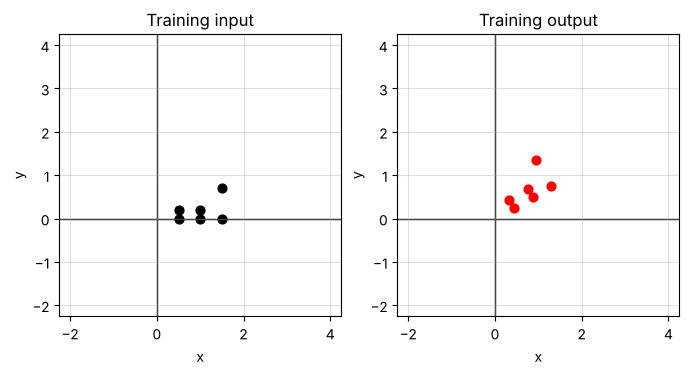

In [2]:
show_training_data(points, rotated)

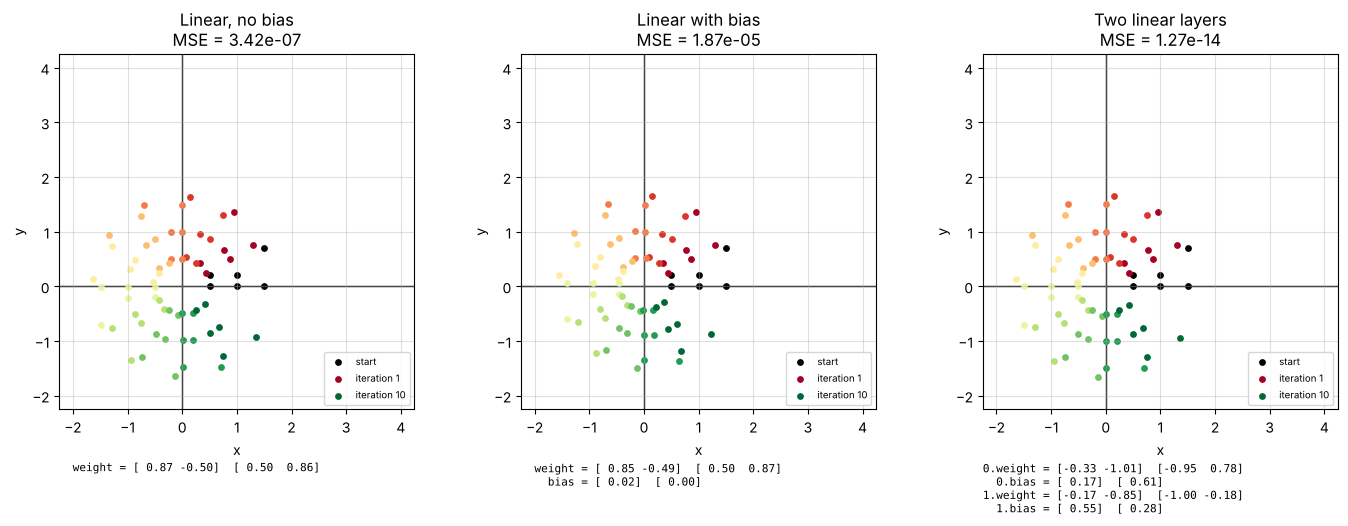

In [3]:
compare_models(points, rotated,
               [nn.Linear(2, 2, bias=False), nn.Linear(2, 2),
                nn.Sequential(nn.Linear(2, 2), nn.Linear(2, 2))],
               ["Linear, no bias", "Linear with bias", "Two linear layers"], steps=1000)

All three models learn the rotation: $W$ approaches
$\begin{pmatrix}\cos 30° & -\sin 30° \\ \sin 30° & \cos 30°\end{pmatrix}
\approx \begin{pmatrix}0.87 & -0.5 \\ 0.5 & 0.87\end{pmatrix}$
and repeated application moves the points around the origin.

## Rotation about another point

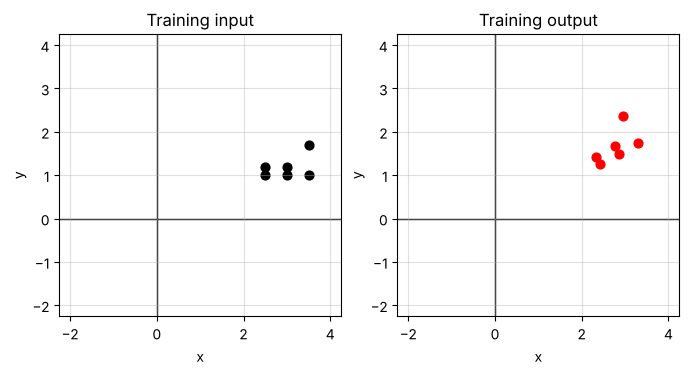

In [4]:
show_training_data(points_shifted, rotated_shifted)

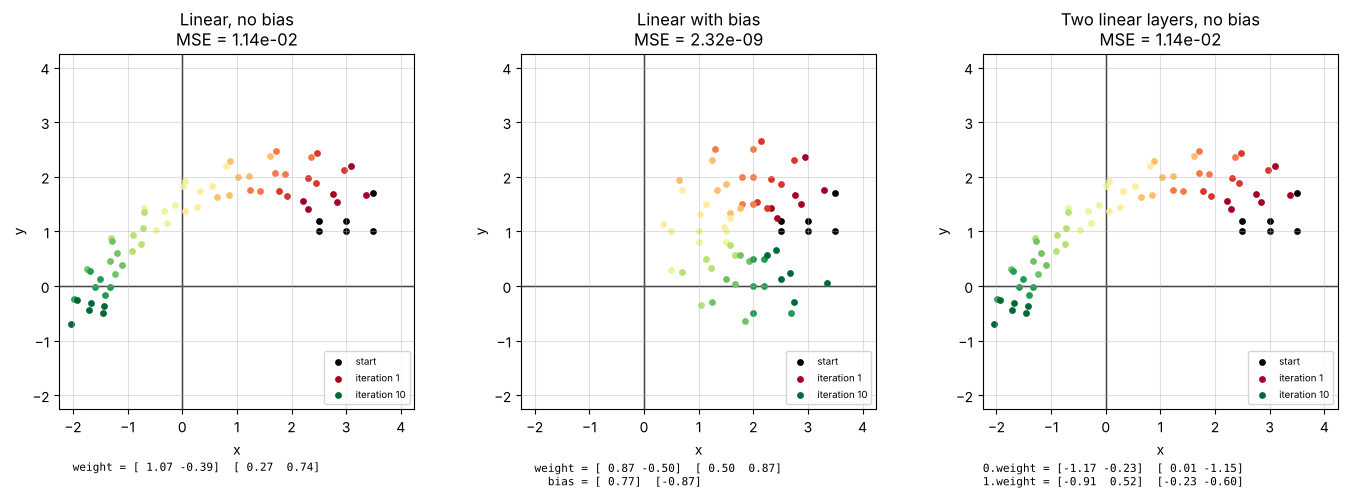

In [5]:
compare_models(points_shifted, rotated_shifted,
               [nn.Linear(2, 2, bias=False), nn.Linear(2, 2),
                nn.Sequential(nn.Linear(2, 2, bias=False), nn.Linear(2, 2, bias=False))],
               ["Linear, no bias", "Linear with bias", "Two linear layers, no bias"], steps=5000)

A rotation about $\mathbf{c} \neq 0$ is $\mathbf{y} = R(\mathbf{x}-\mathbf{c}) + \mathbf{c}
= R\mathbf{x} + (I - R)\mathbf{c}$, i.e. it needs a bias
$\mathbf{b} = (I-R)\mathbf{c}$. Without a bias the network can only find the
best *linear* approximation, and stacking more bias-free linear layers does
not help – their product is still a single matrix.